In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

In [2]:
def show_images(images):
    for name, image in images:
        cv.imshow(name, image)
    cv.waitKey(0)
    cv.destroyAllWindows()


## Analyze image

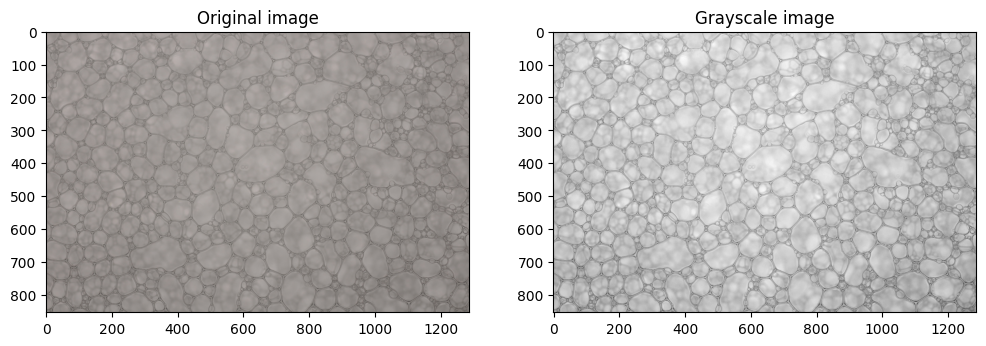

In [3]:
file = 'images/pena.tif'

# load image
img = cv.imread(file)

# resize image
img = cv.resize(img, (0, 0), fx=0.3, fy=0.3)

# keep a copy of the original image
org_img = img.copy()

# convert to grayscale
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# convert to rgb
rgb_img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# show images
plt.figure(figsize=(12, 12))
plt.subplot(1, 2, 1)
plt.title('Original image')
plt.imshow(rgb_img)
plt.subplot(1, 2, 2)
plt.title('Grayscale image')
plt.imshow(gray, cmap='gray')
plt.show()

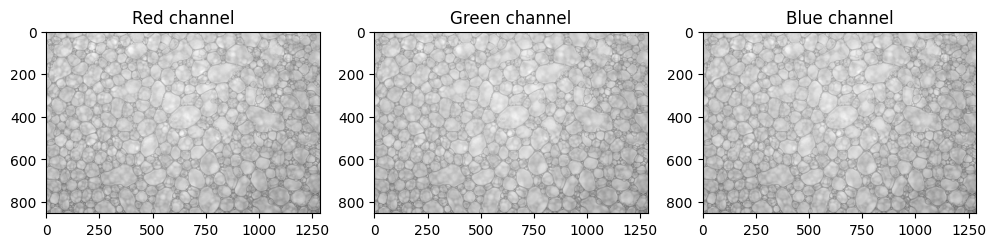

In [4]:
# split channels
b, g, r = cv.split(img)

# show rgb channels
plt.figure(figsize=(12, 12))
plt.subplot(1, 3, 1)
plt.title('Red channel')
plt.imshow(r, cmap='gray')
plt.subplot(1, 3, 2)
plt.title('Green channel')
plt.imshow(g, cmap='gray')
plt.subplot(1, 3, 3)
plt.title('Blue channel')
plt.imshow(b, cmap='gray')
plt.show()

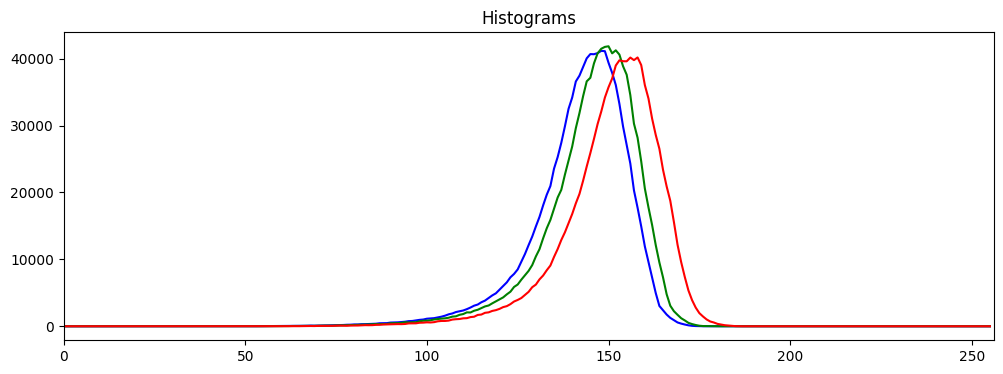

In [5]:
# create histograms
hist_b = cv.calcHist([b], [0], None, [256], [0, 256])
hist_g = cv.calcHist([g], [0], None, [256], [0, 256])
hist_r = cv.calcHist([r], [0], None, [256], [0, 256])

# plot histograms in one figure
plt.figure(figsize=(12, 4))
plt.title('Histograms')
plt.plot(hist_b, color='b')
plt.plot(hist_g, color='g')
plt.plot(hist_r, color='r')
plt.xlim([0, 256])
plt.show()

### Blurring

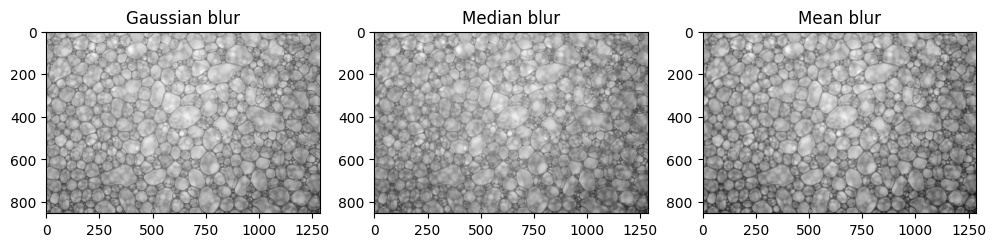

In [6]:
# blur image
gauss = cv.GaussianBlur(gray, (5, 5), 0)
median = cv.medianBlur(gray, 5)
mean = cv.blur(gray, (5, 5))

# show images
plt.figure(figsize=(12, 12))
plt.subplot(1, 3, 1)
plt.title('Gaussian blur')
plt.imshow(gauss, cmap='gray')
plt.subplot(1, 3, 2)
plt.title('Median blur')
plt.imshow(median, cmap='gray')
plt.subplot(1, 3, 3)
plt.title('Mean blur')
plt.imshow(mean, cmap='gray')
plt.show()

### Thresholding

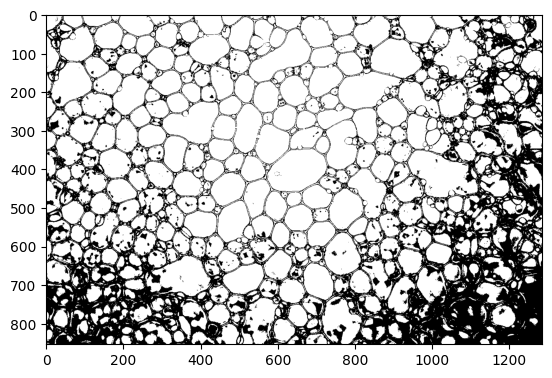

In [7]:
# OTSO threshold
ret, thresh = cv.threshold(gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
plt.imshow(thresh, cmap='gray')

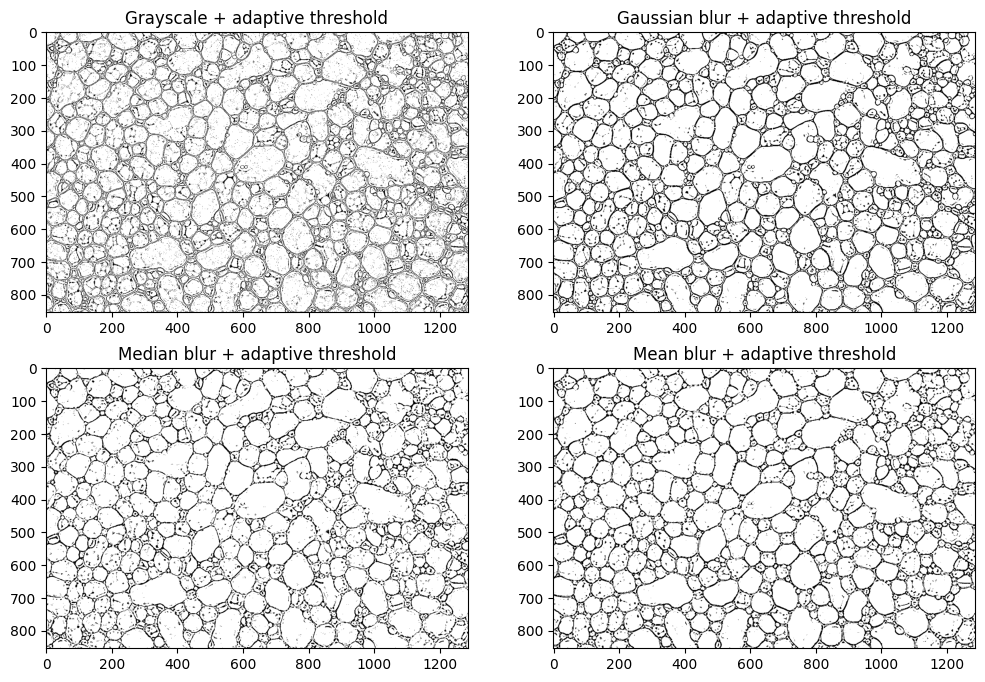

In [8]:
# adaptive threshold
gray_thresh = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)
gauss_thresh = cv.adaptiveThreshold(gauss, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)
median_thresh = cv.adaptiveThreshold(median, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)
mean_thresh = cv.adaptiveThreshold(mean, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)

# show images
plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1)
plt.title('Grayscale + adaptive threshold')
plt.imshow(gray_thresh, cmap='gray')
plt.subplot(2, 2, 2)
plt.title('Gaussian blur + adaptive threshold')
plt.imshow(gauss_thresh, cmap='gray')
plt.subplot(2, 2, 3)
plt.title('Median blur + adaptive threshold')
plt.imshow(median_thresh, cmap='gray')
plt.subplot(2, 2, 4)
plt.title('Mean blur + adaptive threshold')
plt.imshow(mean_thresh, cmap='gray')
plt.show()

### Morphological operations

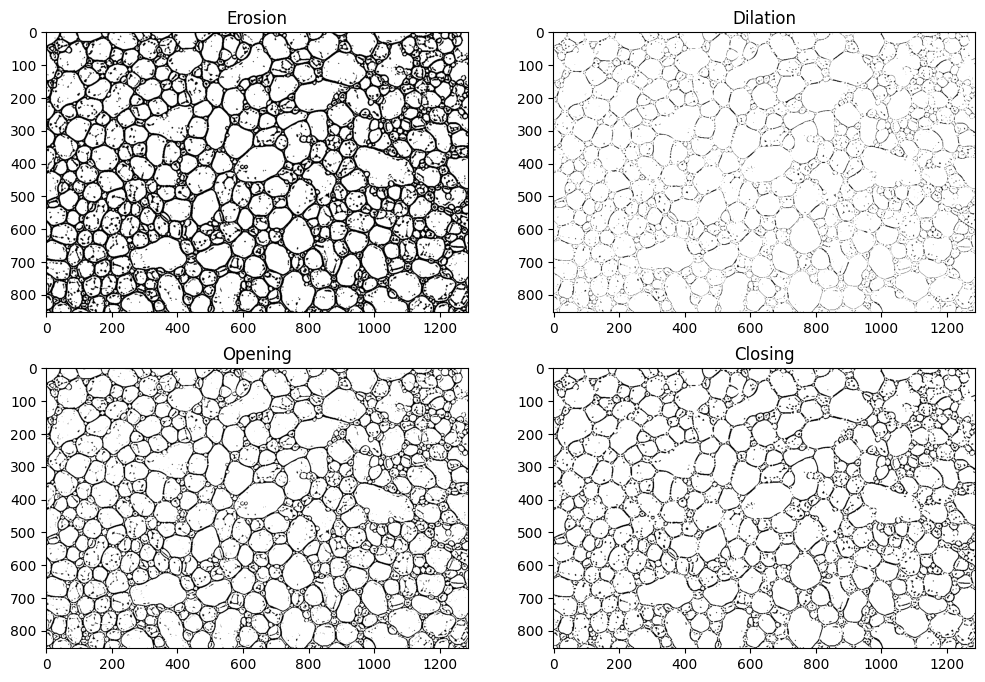

In [9]:
thresh = gauss_thresh
kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))

# morphological operations
erosion = cv.erode(thresh, kernel, iterations=1)
dilation = cv.dilate(thresh, kernel, iterations=1)
opening = cv.morphologyEx(thresh, cv.MORPH_OPEN, kernel)
closing = cv.morphologyEx(thresh, cv.MORPH_CLOSE, kernel)

# plot images
plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1)
plt.title('Erosion')
plt.imshow(erosion, cmap='gray')
plt.subplot(2, 2, 2)
plt.title('Dilation')
plt.imshow(dilation, cmap='gray')
plt.subplot(2, 2, 3)
plt.title('Opening')
plt.imshow(opening, cmap='gray')
plt.subplot(2, 2, 4)
plt.title('Closing')
plt.imshow(closing, cmap='gray')
plt.show()

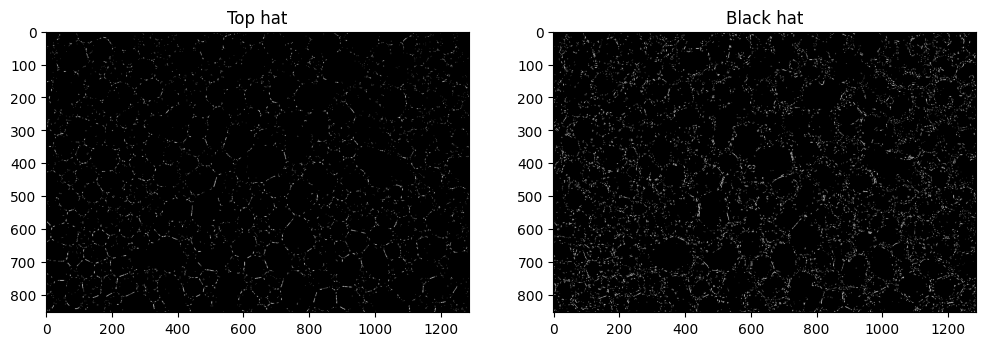

In [10]:
tophat = cv.morphologyEx(gauss_thresh, cv.MORPH_TOPHAT, kernel)
blackhat = cv.morphologyEx(gauss_thresh, cv.MORPH_BLACKHAT, kernel)

# show images
plt.figure(figsize=(12, 8))
plt.subplot(1, 2, 1)
plt.title('Top hat')
plt.imshow(tophat, cmap='gray')
plt.subplot(1, 2, 2)
plt.title('Black hat')
plt.imshow(blackhat, cmap='gray')
plt.show()

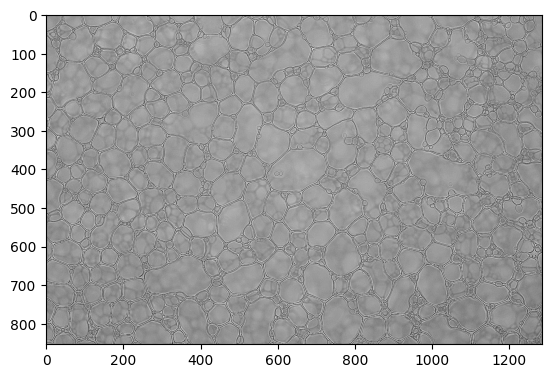

In [11]:
# sharpen image
kernel = np.array([
    [-1, -1, -1],
    [-1, 9, -1],
    [-1, -1, -1]
])
sharp = cv.filter2D(gray, -1, kernel)
plt.imshow(sharp, cmap='gray')

## Method 1

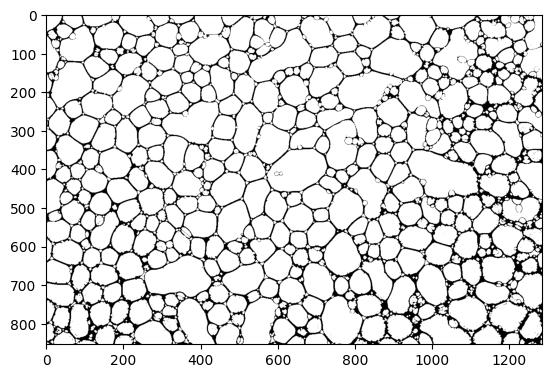

In [12]:
# threshold sharpened image
_, thresh = cv.threshold(sharp, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

# apply morphological opening
kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
opening = cv.morphologyEx(thresh, cv.MORPH_OPEN, kernel, iterations=2)

# dilate image
kernel = np.ones((3, 3), np.uint8)
eroded = cv.erode(opening, kernel, iterations=1)

plt.imshow(opening, cmap='gray')

number of contours: 613


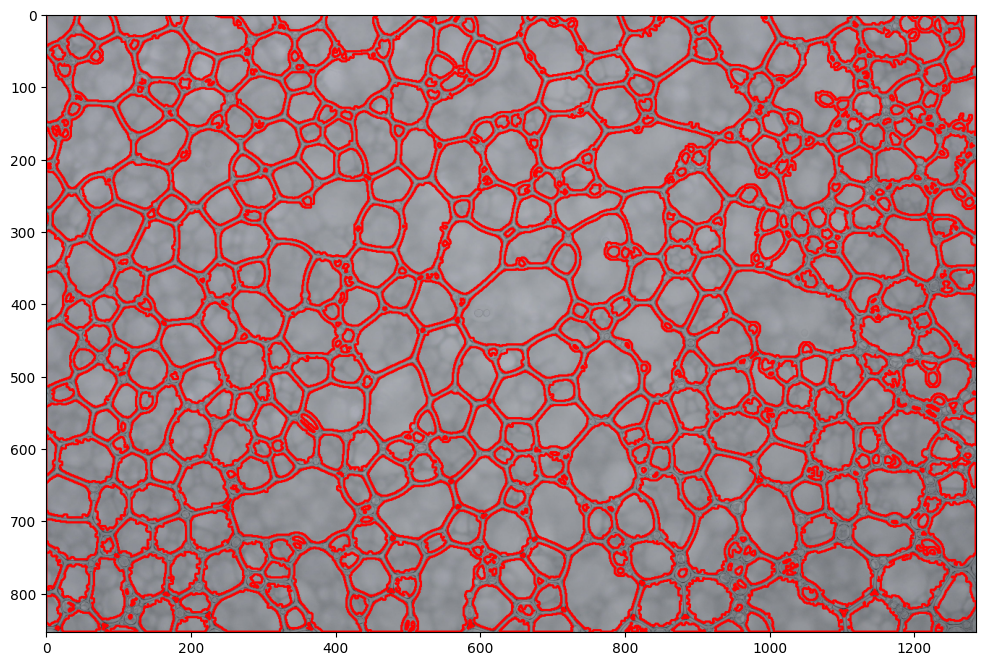

In [13]:
# find contours
contours, hierarchy = cv.findContours(eroded, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

# filter small contours
contours = [c for c in contours if cv.contourArea(c) > 10]

# show contours in image
cont_img = cv.drawContours(img.copy(), contours, -1, (255, 0, 0), 2)
plt.figure(figsize=(12, 12))
plt.imshow(cont_img, cmap='gray')

print(f'number of contours: {len(contours)}')

## Method 2

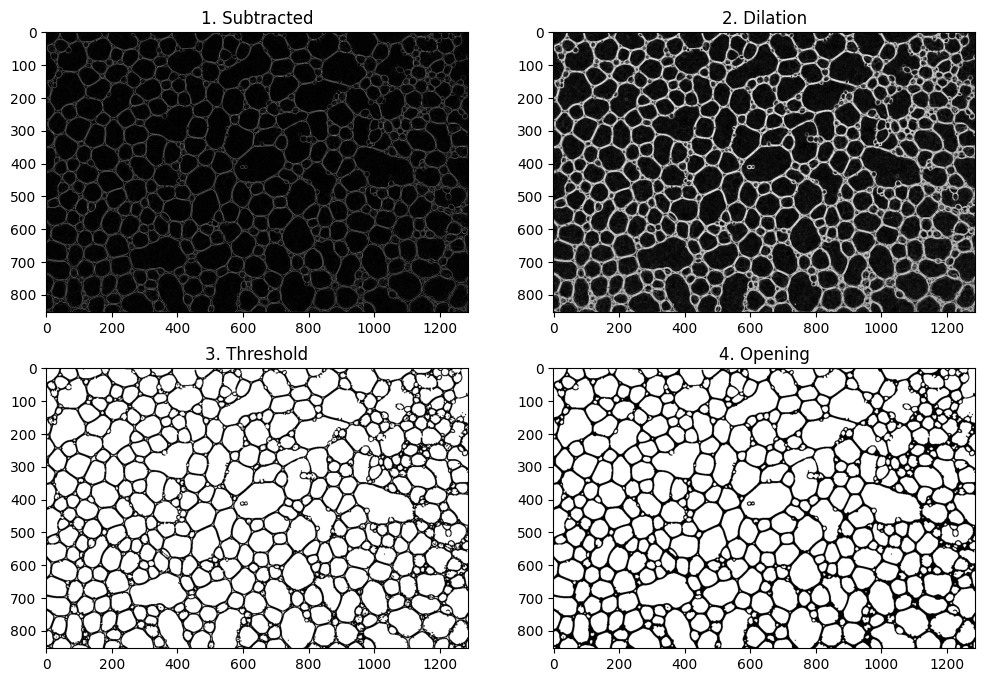

In [14]:
# subtract blurred image from grayscale image
sub = cv.subtract(gray, sharp)

# dilate image
kernel = np.ones((3, 3), np.uint8)
dilation = cv.dilate(sub, kernel, iterations=1)

# threshold dilated image
_, thresh = cv.threshold(dilation, 0, 255, cv.THRESH_BINARY_INV + cv.THRESH_OTSU)

# morphological opening
kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
opening = cv.morphologyEx(thresh, cv.MORPH_OPEN, kernel, iterations=2)

# plot images
plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1)
plt.title('1. Subtracted')
plt.imshow(sub, cmap='gray')
plt.subplot(2, 2, 2)
plt.title('2. Dilation')
plt.imshow(dilation, cmap='gray')
plt.subplot(2, 2, 3)
plt.title('3. Threshold')
plt.imshow(thresh, cmap='gray')
plt.subplot(2, 2, 4)
plt.title('4. Opening')
plt.imshow(opening, cmap='gray')
plt.show()

number of contours: 624


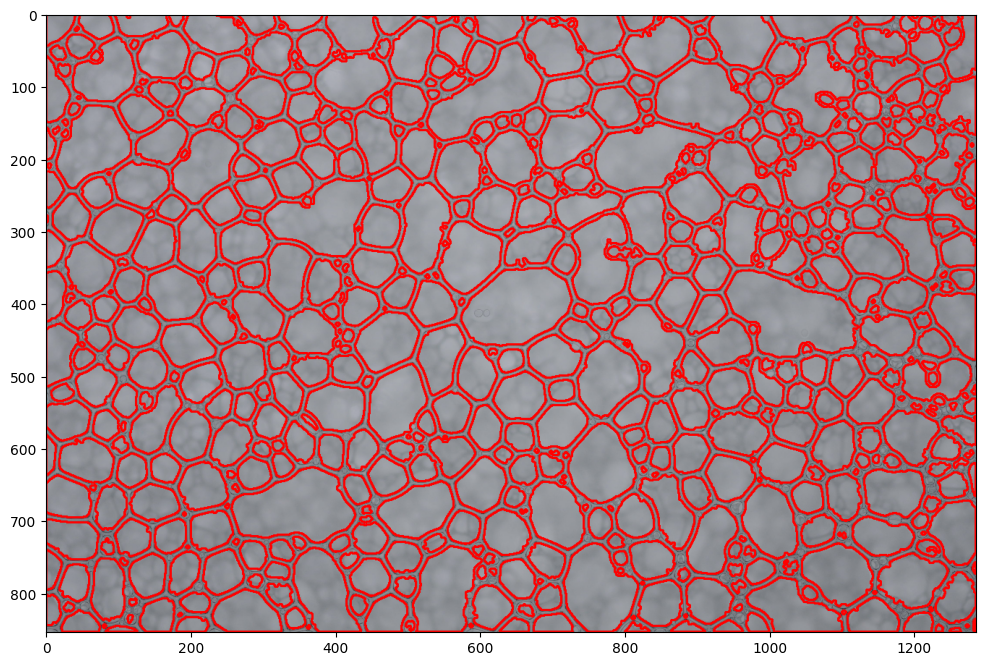

In [15]:
# find contours
contours, _ = cv.findContours(opening, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
contours = [c for c in contours if cv.contourArea(c) > 10]
contour_img = cv.drawContours(img.copy(), contours, -1, (255, 0, 0), 2)

print(f'number of contours: {len(contours)}')

plt.figure(figsize=(12, 12))
plt.imshow(contour_img, cmap='gray')

In [16]:
show_images([
    ['Original', img],
    ['Method 1', cont_img],
    ['Method 2', contour_img],
])